In [1]:
import warnings
import re
import pandas as pd
import numpy as np
import statsmodels.formula.api as sm
import scipy as sc
from statsmodels.iolib.summary import summary
from scipy import stats
import math

Первый кейс (убираем строку для своего варианта урожайность)

Избыточные переменные, линейное ограничение,  тест чоу, RESET test Рамсея, тест на гетероаскедастичность (сборки делаем ручные и проверяем через автоматические сборки в gretl, python, spss)

In [2]:
df = pd.read_csv('urozhaynost_usl_own_varince.csv')

## Тест на избытычность (пошаговый)

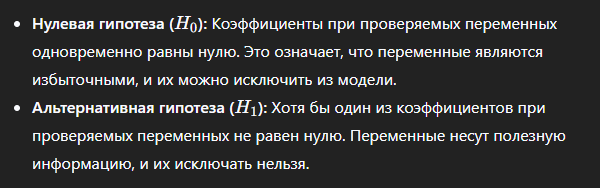

In [3]:
def compare_models(full_model_R, cut_model_R, K1, K2, n):
    df1 = K2 - K1
    df2 = n - K2 - 1
    f_krit = stats.f.ppf(1 - 0.05, df1, df2)
    F = ((full_model_R - cut_model_R) / df1) / ((1 - full_model_R) / df2)
    print(f'F: {F}, F_krit: {f_krit}')
    return F > f_krit



regressors = df.columns[:-1].tolist()
full_model = sm.ols(f'Y ~ {"+".join(regressors)}', df).fit()
start_pvalues = full_model.pvalues[1:]
conf_regressors = set()
while any(np.array(start_pvalues > 0.05)):
    regressor_to_delete = start_pvalues.index[start_pvalues.argmax()]
    print(f'Регрессор {regressor_to_delete}: p_value - {start_pvalues.max()}')
    regressors_without_selected = regressors.copy()
    regressors_without_selected.remove(regressor_to_delete)
    possibility_model = sm.ols(f'Y ~ {"+".join(regressors_without_selected)}', df).fit()
    if compare_models(full_model.rsquared, possibility_model.rsquared, 
                  len(regressors_without_selected), len(regressors), len(df)):
    # F > f_krit → переменная значима, удаление ухудшает модель
        conf_regressors.add(regressor_to_delete)
        full_model = sm.ols(f'Y ~ {"+".join(regressors)}', df).fit()
        start_pvalues = full_model.pvalues[1:].drop(conf_regressors)
        print(f'F-тест значим — переменную нельзя удалять, добавляем в защищённые', end='\n')
    else:
        # F ≤ f_krit → переменная не значима, можно удалять
        regressors.remove(regressor_to_delete)
        full_model = sm.ols(f'Y ~ {"+".join(regressors)}', df).fit()
        start_pvalues = full_model.pvalues[1:]
        print(f'F-тест не значим — удаляем переменную', end='\n')
print('Итоговые регрессоры:' , *regressors)
print('Регрессоры с незначимой p_value, но удаление не дает преимуществ по F-тесту:' , 'Пустой список' if len(conf_regressors) == 0 else conf_regressors)

Регрессор X1: p_value - 0.8997158160988993
F: 0.016513628058174724, F_krit: 4.667192731826847
F-тест не значим — удаляем переменную
Регрессор X2: p_value - 0.6643603627444571
F: 0.19646701336728772, F_krit: 4.600109936669422
F-тест не значим — удаляем переменную
Регрессор X5: p_value - 0.8154453154098568
F: 0.05642931993722524, F_krit: 4.543077165266974
F-тест не значим — удаляем переменную
Итоговые регрессоры: X3 X4
Регрессоры с незначимой p_value, но удаление не дает преимуществ по F-тесту: Пустой список


In [13]:
def compare_models(full_model_R, cut_model_R, K1, K2, n):
    df1 = K2 - K1
    df2 = n - K2 - 1
    f_krit = stats.f.ppf(1 - 0.05, df1, df2)
    F = ((full_model_R - cut_model_R) / df1) / ((1 - full_model_R) / df2)
    p_value = 1 - stats.f.cdf(F, df1, df2)
    print(f'F: {F:.5}, p-value:{p_value:.5}')
    return F > f_krit

def check_for_delete(regressor, df):
    full_model = sm.ols(f'Y ~ {"+".join(df.drop("Y", axis=1).columns)}', df).fit()
    cut_model = sm.ols(f'Y ~ {"+".join(df.drop(["Y", regressor], axis=1).columns)}', df).fit()
    K1 = len(df.drop('Y', axis=1).columns)
    K2 = K1 - 1
    print(f'Удалание регрессора {regressor} из полной модели')
    compare_models(full_model.rsquared, cut_model.rsquared, K2, K1, len(full_model.model.endog))

check_for_delete('X1', df)
check_for_delete('X2', df)
check_for_delete('X3', df)
check_for_delete('X4', df)
check_for_delete('X5', df)

Удалание регрессора X1 из полной модели
F: 0.016514, p-value:0.89972
Удалание регрессора X2 из полной модели
F: 0.13837, p-value:0.7159
Удалание регрессора X3 из полной модели
F: 0.081134, p-value:0.78025
Удалание регрессора X4 из полной модели
F: 5.6941, p-value:0.032923
Удалание регрессора X5 из полной модели
F: 0.1497, p-value:0.70509


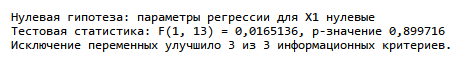
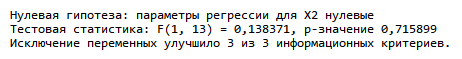
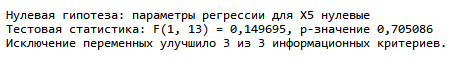

## Тест на линейные ограничения

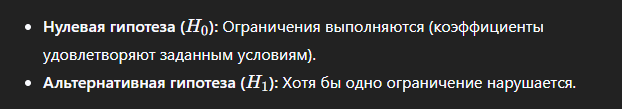

In [14]:
def compare_models_linear(full_model, restricted_model, J, alpha=0.05):
    n = len(full_model.model.endog)  # количество наблюдений
    K_full = full_model.df_model      # количество параметров в полной модели
    RSS_full = full_model.ssr         # остаточная сумма квадратов полной модели
    RSS_restr = restricted_model.ssr  # остаточная сумма квадратов ограниченной модели
    df1 = J                          # числитель: количество ограничений
    df2 = n - K_full - 1             # знаменатель: степени свободы полной модели
    f_krit = stats.f.ppf(1 - alpha, df1, df2)
    F = ((RSS_restr - RSS_full) / df1) / (RSS_full / df2)
    p_value = 1 - stats.f.cdf(F, df1, df2)
    print(f'F: {F:.4f}, F_krit: {f_krit:.4f}, p-value: {p_value:.4f}')
    return F > f_krit


def linear_restricts(df, R_matrix_for_restricted):
    full_model = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}', df).fit()
    changed_df = df.copy()

    restrictions = R_matrix_for_restricted.split(',')
    J = len(restrictions)

    for restriction in restrictions:
        left, right = restriction.split('=')
        q = float(right.strip())
        terms = re.findall(r'([+-]?\s*[\d.]*)\*?(\w+)', left)
        
        if len(terms) == 1 and q == 0:
            # Простое ограничение: переменная = 0
            _, var = terms[0]
            if var in changed_df.columns:
                changed_df = changed_df.drop(columns=[var])
        elif len(terms) == 2 and q == 0:
            # Ограничение вида c1*β1 + c2*β2 = 0
            coef1_str, var1 = terms[0]
            coef2_str, var2 = terms[1]
            
            coef1_str = coef1_str.replace(' ', '')
            coef2_str = coef2_str.replace(' ', '')
            
            coef1 = float(coef1_str) if coef1_str not in ['', '+'] else 1
            if coef1_str == '-':
                coef1 = -1
                
            coef2 = float(coef2_str) if coef2_str not in ['', '+'] else 1
            if coef2_str == '-':
                coef2 = -1
            ratio = coef2 / coef1
            z_expr = f'`{var2}` - {ratio}*`{var1}`'
            z_name = f'Z_{var1}_{var2}'
            
            changed_df[z_name] = changed_df.eval(z_expr)
            changed_df = changed_df.drop(columns=[var1, var2])
        else:
            print(f'⚠️ Ограничение "{restriction}" не поддерживается')
            return
    restricted_predictors = [c for c in changed_df.columns if c != 'Y']
    restricted_model = sm.ols(f'Y ~ {"+".join(restricted_predictors)}', changed_df).fit()

    results = compare_models_linear(full_model, restricted_model, J)
    if results:
        print('Ограничения нарушаются')
    else:
        print('Ограничения не нарушаются')


linear_restricts(df, '1*X3 + 2*X4 = 0')
linear_restricts(df, 'X1=0, X2=0, X5=0')

F: 5.4194, F_krit: 4.6672, p-value: 0.0367
Ограничения нарушаются
F: 0.0829, F_krit: 3.4105, p-value: 0.9681
Ограничения не нарушаются


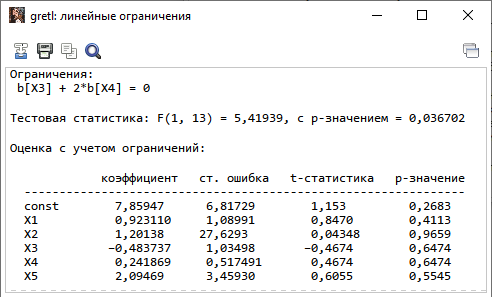

## Тест Чоу

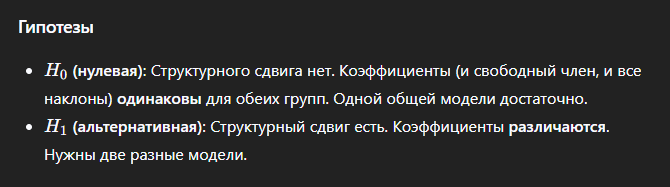

In [6]:
df = pd.read_csv('urozhaynost_usl_own_varince.csv')

def compare_models_choy(full_model, model_1, model_2, alpha=0.05):
    n = len(full_model.model.endog)
    k = full_model.df_model + 1
    n1 = len(model_1.model.endog)
    n2 = len(model_2.model.endog)

    RSS_full = full_model.ssr
    RSS_1 = model_1.ssr
    RSS_2 = model_2.ssr

    df1 = k
    df2 = n - 2 * k
    f_krit = stats.f.ppf(1 - alpha, df1, df2)
    F = ((RSS_full - (RSS_1 + RSS_2)) / df1) / ((RSS_1 + RSS_2) / df2)
    p_value = 1 - stats.f.cdf(F, df1, df2)
    print(f'F: {F:.4f}, F_krit: {f_krit:.4f}, p-value: {p_value:.4f}')
    return F > f_krit



def test_choy(df, index_for_devide):
    df_choy = df.copy()
    index_for_devide -= 1
    df_1, df_2 = df_choy.iloc[:index_for_devide], df_choy.iloc[index_for_devide:]
    model_1 = sm.ols(f'Y ~ {"+".join(df_1.columns[:-1])}', df_1).fit()
    model_2 = sm.ols(f'Y ~ {"+".join(df_2.columns[:-1])}', df_2).fit()
    full_model = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}', df_choy).fit()

    if compare_models_choy(full_model, model_1, model_2):
        print('Структурный сдвиг есть. Коэффициенты различаются. Нужны две разные модели.')
    else:
        print('Структурного сдвига нет. Коэффициенты (и свободный член, и все наклоны) одинаковы для обеих групп. Одной общей модели достаточно.')


test_choy(df, 10)

F: 0.2319, F_krit: 3.8660, p-value: 0.9526
Структурного сдвига нет. Коэффициенты (и свободный член, и все наклоны) одинаковы для обеих групп. Одной общей модели достаточно.


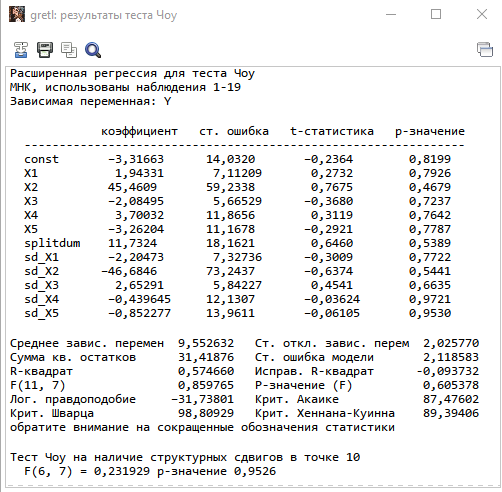

## Тест Рамсея (Ramsey’s RESET test)

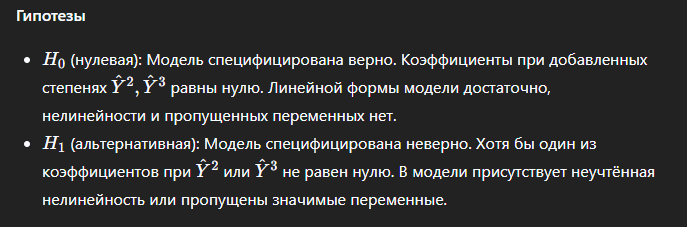

In [7]:
def compare_models_reset(restricted_model, full_model, J, alpha=0.05):
    n = len(full_model.model.endog)
    K_full = full_model.df_model
    RSS_full = full_model.ssr
    RSS_restr = restricted_model.ssr
    df1 = J
    df2 = n - K_full - 1
    f_krit = stats.f.ppf(1 - alpha, df1, df2)
    F = ((RSS_restr - RSS_full) / df1) / (RSS_full / df2)
    p_value = 1 - stats.f.cdf(F, df1, df2)
    print(f'F: {F:.4f}, F_krit: {f_krit:.4f}, p-value: {p_value:.4f}')
    return F > f_krit



df = pd.read_csv('urozhaynost_usl_own_varince.csv')
full_model = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}',df).fit()
df['y2'] = full_model.predict(df.drop(columns=['Y'])) ** 2
df['y3'] = full_model.predict(df.drop(columns=['Y'])) ** 3
model_for_check = sm.ols(f'Y ~ {"+".join(df.drop(columns=["Y"]))}', df).fit()
if compare_models_reset(full_model, model_for_check, 2):
    print('Модель специфицирована неверно, нужно добавлять нелинейности или пропущенные переменные')
else:
    print('Модель специфицирована верно')

F: 1.9354, F_krit: 3.9823, p-value: 0.1905
Модель специфицирована верно


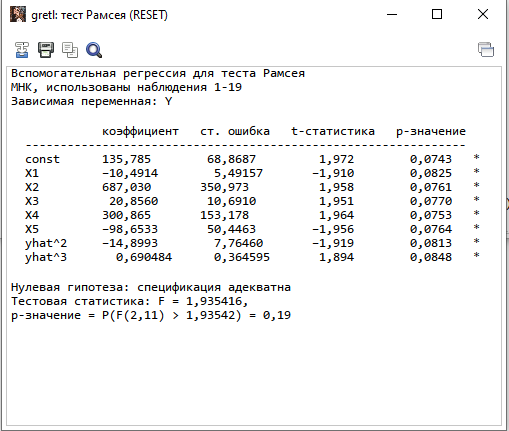

## Тест на гетероскедастичность

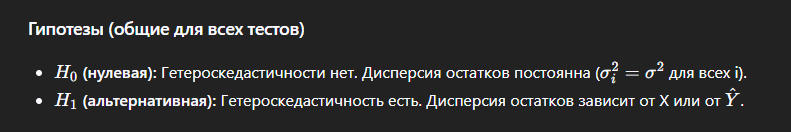

Тест Уайта

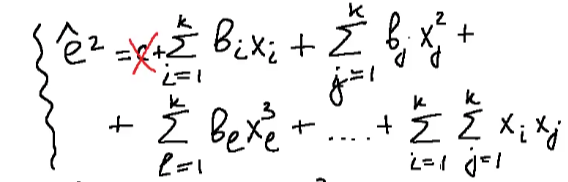
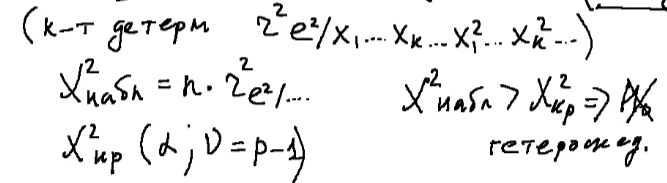

In [8]:
df = pd.read_csv('urozhaynost_usl_own_varince.csv')
full_model = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}', df).fit()
rss = full_model.resid ** 2

df_for_test = df.copy().drop('Y', axis=1)

for col in df.columns[:-1]:
    df_for_test[f'{col}_sq'] = df[col] ** 2
    df_for_test[f'{col}_cb'] = df[col] ** 3
    for other_col in df.drop([col, 'Y'], axis=1).columns:
        if f'{other_col}_{col}' in df_for_test.columns:
            continue
        df_for_test[f'{col}_{other_col}'] = df[col] * df[other_col]

df_for_test['e'] = rss
model_by_resid = sm.ols(f'e ~ {"+".join(df_for_test.drop("e", axis=1).columns)}', df_for_test).fit()
model_by_resid.summary()

C:\Users\Валерий\AppData\Local\Temp\ipykernel_6520\416315132.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_by_resid = sm.ols(f'e ~ {"+".join(df_for_test.drop("e", axis=1).columns)}', df_for_test).fit()
C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:2032: RuntimeWarning: divide by zero encountered in divide
  np.divide(self.nobs - self.k_constant, self.df_resid) * (1 - self.rsquared)
C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:2032: RuntimeWarning: invalid value encountered in scalar multiply
  np.divide(self.nobs - self.k_constant, self.df_resid) * (1 - self.rsquared)
C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:1954: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresi

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      e   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Mon, 26 Oct 2026   Prob (F-statistic):                nan
Time:                        19:04:55   Log-Likelihood:                 474.37
No. Observations:                  19   AIC:                            -910.7
Df Residuals:                       0   BIC:                            -892.8
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -52.5106        inf         -0        nan         nan         nan
X1           109.0014        inf          0        nan         nan         nan
X2           167.1413        inf          0        nan         nan         nan
X3           -46.9350        inf         -0        nan         nan         nan
X4             4.3363        inf          0        nan         nan         nan
X5           -31.7685        inf         -0        nan         nan         nan
X1_sq        -37.5479        inf         -0        nan         nan         nan
X1_cb         -2.9495        inf         -0        nan         nan         nan
X1_X2       -231.1274        inf         -0        nan         nan         nan
X1_X3         64.4138        inf          0        nan         nan         nan
X1_X4        -73.3594        inf         -0        nan         nan         nan
X1_X5         91.6639        inf          0        nan         nan         nan
X2_sq         99.1050        inf          0        nan         nan         nan
X2_cb         44.2537        inf          0        nan         nan         nan
X2_X3        -11.9666        inf         -0        nan         nan         nan
X2_X4        149.9539        inf          0        nan         nan         nan
X2_X5         98.7956        inf          0        nan         nan         nan
X3_sq        -20.8070        inf         -0        nan         nan         nan
X3_cb          1.3271        inf          0        nan         nan         nan
X3_X4         54.5906        inf          0        nan         nan         nan
X3_X5        -96.5065        inf         -0        nan         nan         nan
X4_sq       -153.6356        inf         -0        nan         nan         nan
X4_cb         98.4254        inf          0        nan         nan         nan
X4_X5        207.1349        inf          0        nan         nan         nan
X5_sq        -30.5912        inf         -0        nan         nan         nan
X5_cb       -159.1310        inf         -0        nan         nan         nan
==============================================================================
Omnibus:                       43.314   Durbin-Watson:                   2.189
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              142.357
Skew:                          -3.489   Prob(JB):                     1.22e-31
Kurtosis:                      14.451   Cond. No.                     1.79e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The input rank is higher than the number of observations.
[3] The condition number is large, 1.79e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Тест Уайта только с квадратами

In [22]:
df = pd.read_csv('urozhaynost_usl_own_varince.csv')
full_model = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}', df).fit()
rss = full_model.resid ** 2

df_for_test = df.copy().drop('Y', axis=1)
for col in df.columns[:-1]:
    df_for_test[f'{col}_sq'] = df[col] ** 2

df_for_test['e'] = rss
model_by_resid = sm.ols(f'e ~ {"+".join(df_for_test.drop("e", axis=1).columns)}', df_for_test).fit()

# Статистика хи-квадрат (тест Уайта)
n = len(df)
R2_aux = model_by_resid.rsquared
TR2 = n * R2_aux
df_chi2 = len(df_for_test.drop("e", axis=1).columns)
# p-value
p_value = 1 - stats.chi2.cdf(TR2, df_chi2)

print(f'\nТест Уайта:')
print(f'TR² = {TR2:.6f}')
print(f'Степени свободы = {df_chi2}')
print(f'p-value = P(Chi-квадрат({df_chi2}) > {TR2:.6f}) = {p_value:.6f}')

if p_value < 0.05:
    print('➡️ Гетероскедастичность ОБНАРУЖЕНА')
else:
    print('➡️ Гетероскедастичность не обнаружена')


Тест Уайта:
TR² = 12.293895
Степени свободы = 10
p-value = P(Chi-квадрат(10) > 12.293895) = 0.265869
➡️ Гетероскедастичность не обнаружена


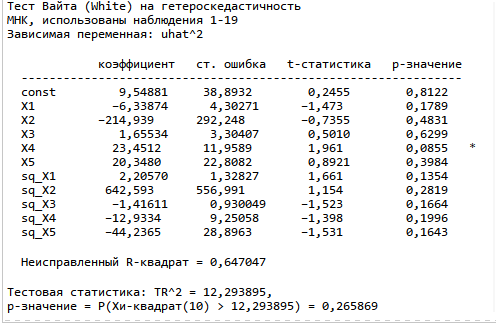

Тест Голдфельда-Квандта

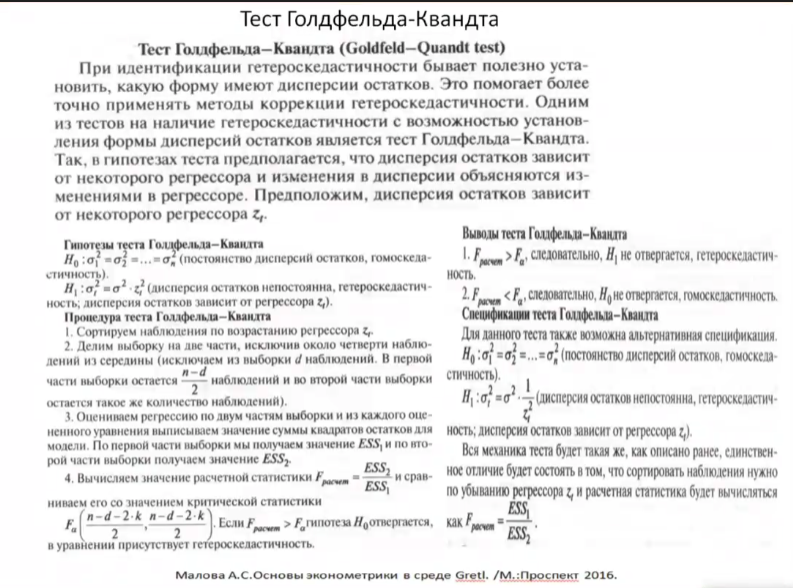

In [10]:
def compare_models_golf(model_1, model_2, alpha=0.05):
    RSS_1 = model_1.ssr
    RSS_2 = model_2.ssr
    n1 = len(model_1.model.endog)
    n2 = len(model_2.model.endog)
    k = model_1.df_model + 1
    df1 = n1 - k
    df2 = n2 - k
    if RSS_1 == 0 or df1 <= 0 or df2 <= 0:
        print('Тест неприменим (RSS_1=0 или степени свободы ≤ 0)')
        return None
    f_krit = stats.f.ppf(1 - alpha, df2, df1)
    F = (RSS_2 / df2) / (RSS_1 / df1)
    p_value = 1 - stats.f.cdf(F, df2, df1)
    print(f'F: {F:.4f}, F_krit: {f_krit:.4f}, p-value: {p_value:.4f}')
    return F > f_krit
    


df = pd.read_csv('urozhaynost_usl_own_varince.csv')
regressors = df.columns[:-1]
for reg in regressors:
    df_current = df.sort_values(by=reg)
    rows_to_delete = round(len(df) * 0.1)
    df_1, df_2 = df_current[:math.ceil(len(df) / 2) - rows_to_delete], df_current[math.ceil(len(df) / 2) + rows_to_delete - 1:]
    model_1 = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}', df_1).fit()
    model_2 = sm.ols(f'Y ~ {"+".join(df.columns[:-1])}', df_2).fit()
    print(f'По регрессору {reg}:')
    if compare_models_golf(model_1, model_2):
        print('Была выявлена гетероскедастичность')
    else:
        print('Дисперсия остатков гомоскедастична')

По регрессору X1:
F: 0.5939, F_krit: 19.0000, p-value: 0.6274
Дисперсия остатков гомоскедастична
По регрессору X2:
F: 5.3198, F_krit: 19.0000, p-value: 0.1582
Дисперсия остатков гомоскедастична
По регрессору X3:
F: 2.2840, F_krit: 19.0000, p-value: 0.3045
Дисперсия остатков гомоскедастична
По регрессору X4:
F: 10.0521, F_krit: 19.0000, p-value: 0.0905
Дисперсия остатков гомоскедастична
По регрессору X5:
F: 8.5503, F_krit: 19.0000, p-value: 0.1047
Дисперсия остатков гомоскедастична
